<p>Octavio Vieyra Orozco<p>
<p>Maestría en Ciencia de datos<p>

<h1>Modelos de Machine Learning</h1>

In [1]:
# Importar Librerias de apoyo
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

<h3>Regresión Lineal</h3>

In [2]:
# Importar algoritmo para RL
from sklearn.linear_model import LinearRegression

In [3]:
# Necesitamos la Función train_test_split para dividir el dataset de prueba y entrenamiento
from sklearn.model_selection import train_test_split

In [4]:
# Importamos conjunto de métricas para validar el modelo
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [5]:
# Creamos un Data Set sintético
# Salario = 25000 + 5000 * Años_de_Exp + ruido/error
# Utilizamos numero aleatorios
np.random.seed(42)
x = np.random.randint(1,21,100).reshape(-1,1)

In [6]:
# Generamos ruido o errores para la generación del dataset sintético
ruido = np.random.normal(0, 5000, 100)

In [7]:
# Generamos los valores de Y
y = 25000 + 5000 * x.flatten() + ruido

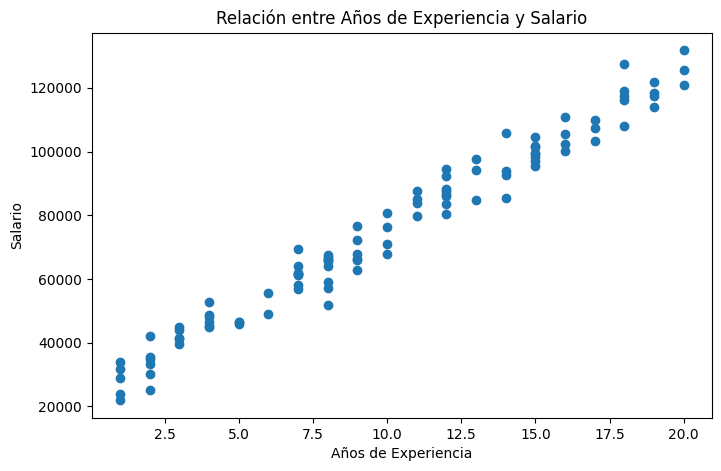

In [8]:
# Graficamos los datos
plt.figure(figsize=(8,5))
plt.scatter(x, y)
plt.xlabel('Años de Experiencia')
plt.ylabel('Salario')
plt.title('Relación entre Años de Experiencia y Salario')
plt.show()

In [9]:
#Dividimos el dataset en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [10]:
#  Iniciamos el algoritmo de Regresión Lineal
modelo = LinearRegression()

In [11]:
# Entrenamos el modelo con los datos de entrenamiento
modelo.fit(X_train, y_train)

LinearRegression()

In [12]:
# Obtenemos los parametros del modelo
print(" Intercepción (b0):", modelo.intercept_)
print(" Pendiente (b1):", modelo.coef_[0])


 Intercepción (b0): 24735.85817689666
 Pendiente (b1): 5054.407331752709


In [13]:
# Hacer predicciones con los datos de prueba
y_pred = modelo.predict(X_test)

In [14]:
#  Visuailzamos los resultados y comparamos
for real, predicho in zip (y_test[:10], y_pred[:10]):
    print(f"Real: {real:.2f}, Predicho: {predicho:.2f}")

Real: 103397.72, Predicho: 110660.78
Real: 49156.61, Predicho: 55062.30
Real: 95402.88, Predicho: 100551.97
Real: 39627.77, Predicho: 39899.08
Real: 101287.75, Predicho: 100551.97
Real: 120988.61, Predicho: 125824.00
Real: 104577.01, Predicho: 100551.97
Real: 66299.41, Predicho: 65171.12
Real: 51901.27, Predicho: 65171.12
Real: 64062.63, Predicho: 60116.71


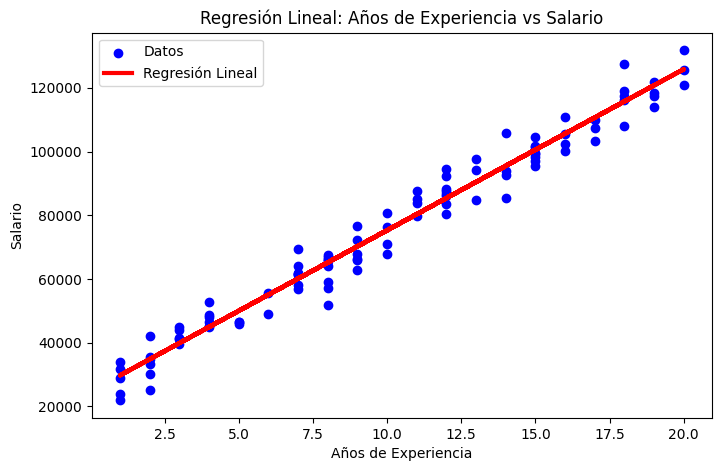

In [15]:
# Graficamos el modelo generado
plt.figure(figsize=(8,5))
plt.scatter(x, y, color='blue', label='Datos')
plt.plot(x, modelo.predict(x), color='red', linewidth=3 ,label='Regresión Lineal')
plt.xlabel('Años de Experiencia')
plt.ylabel('Salario')
plt.title('Regresión Lineal: Años de Experiencia vs Salario')
plt.legend()
plt.show()

In [16]:
#Evaluamos el modelo
# comenzamos con el MAE (Mean Absolute Error) / Error Absoluto Medio, sirve para medir la magnitud de los errores en un conjunto de predicciones, sin considerar su dirección. Es la media de las diferencias absolutas entre las predicciones y los valores reales.
mae = mean_absolute_error(y_test, y_pred)
print(f"Error Absoluto Medio (MAE): {mae:.2f}")

Error Absoluto Medio (MAE): 3840.50


In [17]:
# Calculamos el Error Cuadrado Medio, sirve para medir la diferencia entre los valores predichos y los valores reales
mse = mean_squared_error(y_test, y_pred)
print(f"Error Cuadrado Medio (MSE): {mse:.2f}")

Error Cuadrado Medio (MSE): 25411312.47


In [18]:
# Calculamos el Coeficiente de Determinación (R^2), que indica qué tan bien se ajusta el modelo a los datos. Un valor cercano a 1 indica un buen ajuste.
r2 = r2_score(y_test, y_pred)
print(f"Coeficiente de Determinación (R^2): {r2}")

Coeficiente de Determinación (R^2): 0.9594169633031285


<h3>Decision Tree</h3>

In [19]:
# Librerias Apoyo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [20]:
#Cargar el dataset de deserción
dataset = pd.read_csv('/Users/octaviovieyra/Downloads/dataset_desercion_1000.csv')

In [21]:
# Importar el algoritmo de arboles de decisión
from sklearn.tree import DecisionTreeClassifier

In [22]:
# Importar metricas de evaluación
from sklearn.metrics import accuracy_score, classification_report

In [23]:
# Importar la función de división de datos
from sklearn.model_selection import train_test_split

In [24]:
# Dividimos el dataset en características (X) y variable objetivo (y)
X = dataset.drop('desercion', axis=1) # todos los atributos excepto la columna 'Desercion' (solo la información)
y = dataset['desercion'] # la columna 'Desercion' es nuestra variable objetivo

In [25]:
# Dividimos el datase en entrenamiento y prueba (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [26]:
# Entrenamos el modelo de árbol de decisión
modelo_arbol = DecisionTreeClassifier(max_depth=6, random_state=42)
modelo_arbol.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=6, random_state=42)

In [27]:
#Evaluamos el modelo con los datos de prueba
y_pred = modelo_arbol.predict(X_test)
print("Accuracy: ", accuracy_score(y_test, y_pred))
print("\nReporte clasificación\n",classification_report(y_test, y_pred))

Accuracy:  0.64

Reporte clasificación
               precision    recall  f1-score   support

           0       0.61      0.70      0.65        96
           1       0.68      0.59      0.63       104

    accuracy                           0.64       200
   macro avg       0.64      0.64      0.64       200
weighted avg       0.64      0.64      0.64       200



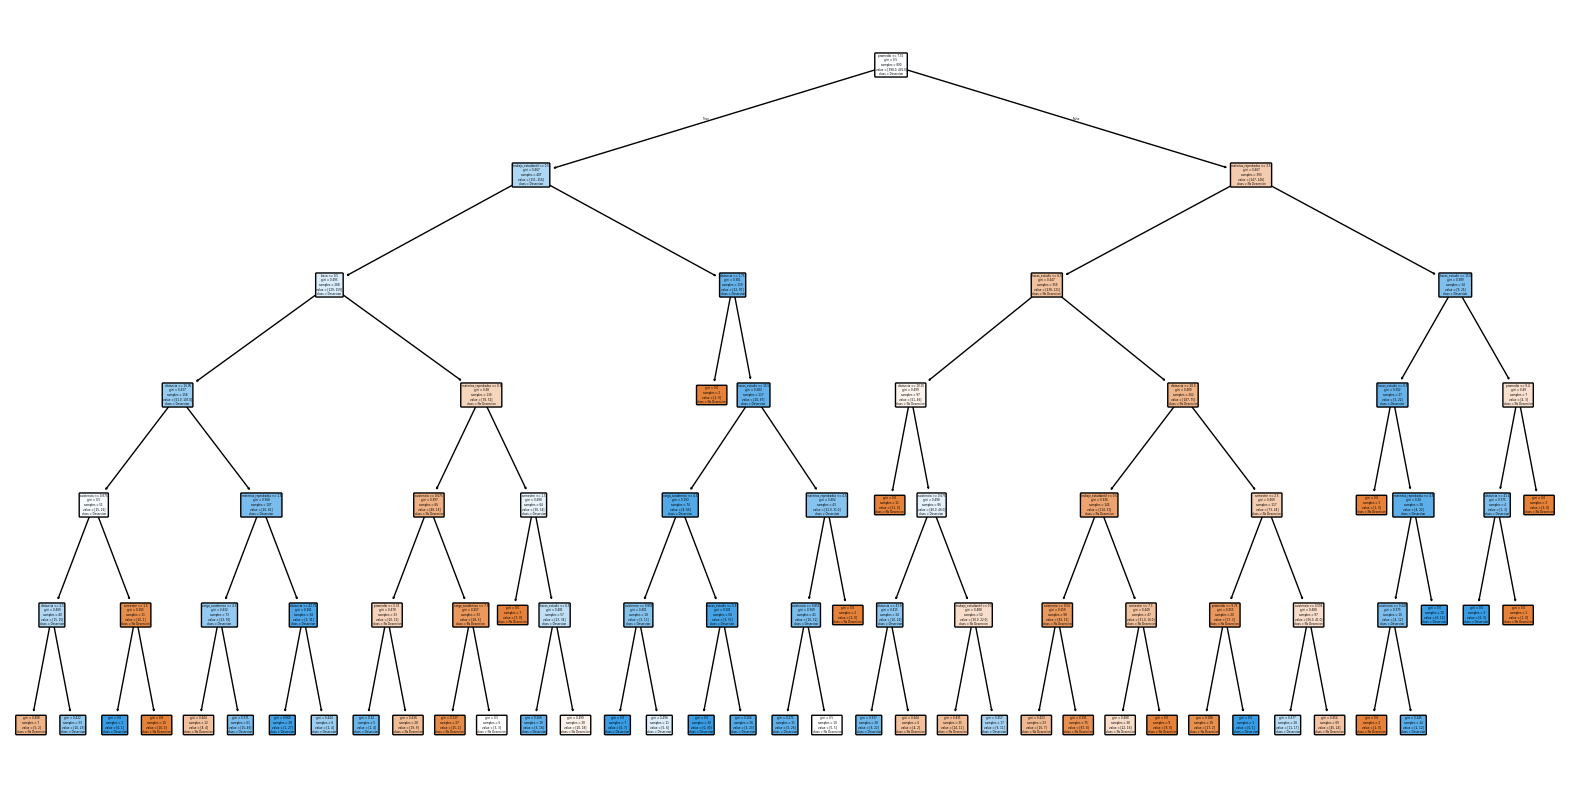

In [28]:
# Visualizamos el arbol
from sklearn.tree import plot_tree
plt.figure(figsize=(20,10))
plot_tree(modelo_arbol, feature_names=X.columns, class_names=['No Desercion', 'Desercion'], filled=True, rounded=True)
plt.show()

Usar los dato del crp o de categoria colegio para los dos modelos, para el knn y Random forest

<h3>KNN</h3>

In [29]:
# Librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [30]:
# Cargar el dataset
colegios = pd.read_excel("/Users/octaviovieyra/Downloads/Kn_Vision_by_Colegios.xlsx")
# Dimensiones del dataset
print("Dimensiones del dataset:", colegios.shape)

Dimensiones del dataset: (288, 9)


In [31]:
# Ver el dataser
colegios.head()

,Colegio,Kn Code,Val MOVS,Val MAT,Val CRP,Val SOL,Val M/U,Total Val,Segmento
0,Colegio Salesiano Don Bosco de Sahuayo,MX-MIC-0434,0,-1,1,4,2.0,2.10,2
1,Colegio Inglés Durkheim (Plantel Kínder Polanco),MX-CMX-0467,0,1,1,1,2.9,1.76,2
2,Instituto México,MX-SLP-0460,0,-1,1,4,2.3,2.22,2
3,Colegio Guadalupe de Guadalajara A.C.,MX-JAL-0424,0,-1,1,4,3.6,2.74,3
4,"Colegio Bilingüe ""Petit Academy"" de Green Hills",MX-COA-0412,0,-1,1,4,2.6,2.34,3


In [32]:
# Importar el algoritmo de Knn
from sklearn.neighbors import KNeighborsClassifier

In [33]:
# Estandarizamos las variables (media 0 y desviación estándar 1)
# Es importante para algoritmos sensibles a la escala como KNN
from sklearn.preprocessing import StandardScaler

In [34]:
# Importar metricas de evaluación
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [35]:
# Importar la función de división de datos
from sklearn.model_selection import train_test_split

In [36]:
# Seleccionamos las características (X) y la variable objetivo (y)
# Valores de X son las columnas de características
X = colegios[['Val MOVS', 'Val MAT', 'Val CRP', 'Val SOL', 'Val M/U']]
# Valores de y es la columna de clasificación
y = colegios['Segmento']
# Valores X
X.head()

,Val MOVS,Val MAT,Val CRP,Val SOL,Val M/U
0,0,-1,1,4,2.0
1,0,1,1,1,2.9
2,0,-1,1,4,2.3
3,0,-1,1,4,3.6
4,0,-1,1,4,2.6


In [37]:
# Se divide el dataset en entrenamiento y prueba (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) #stratify=y para mantener la proporción de clases en ambos conjuntos

print("Dimensiones del conjunto de entrenamiento:", X_train.shape)
print("Dimensiones del conjunto de prueba:", X_test.shape)

Dimensiones del conjunto de entrenamiento: (230, 5)
Dimensiones del conjunto de prueba: (58, 5)


In [38]:
# Se crea instancia de StandardScaler
scaler = StandardScaler() # Este se crea con el objetivo de estandarizar los datos, es decir, que tengan media 0 y desviación estándar 1
# Se ajusta el scaler a los datos de entrenamiento y se transforma
X_train_scaled = scaler.fit_transform(X_train) # fit_transform ajusta el scaler a los datos de entrenamiento y luego transforma esos datos (Solo con X_train)
# Transforma los datos de prueba usando los parámetros aprendidos en el entrenamiento
# Importante: aquí NO se recalcula la media ni la desviación, solo se aplica la transformación
X_test_scaled = scaler.transform(X_test) # transform transforma los datos de prueba usando el mismo scaler ajustado con X_train

In [39]:
# Definir el modelo KNN con k=4 vecinos
# Este valor de k es un punto de partida común, pero puede ajustarse según la validación cruzada o el rendimiento del modelo
k_inicial = 4
# metric='euclidean' indica que se usará la distancia euclidiana para calcular la cercanía entre puntos
knn = KNeighborsClassifier(n_neighbors=k_inicial, metric='euclidean') 
# Se entrena el modelo utilizando los datos de entrenamiento ya escalados
# X_train_scaled: variables de entrada normalizadas
# y_train: etiquetas correspondientes
knn.fit(X_train_scaled, y_train)
# Se realizan predicciones sobre los datos de prueba escalados
# El modelo asigna una clase a cada observación de X_test_scaled
y_pred = knn.predict(X_test_scaled)
# Se calcula la precisión del modelo
# accuracy_score compara las predicciones (y_pred) con los valores reales (y_test)
precision = accuracy_score(y_test, y_pred) #Es la comparación entre ambas para acertar a la precisón
print(f"Precisión con K={k_inicial}: {precision:.4f}")

Precisión con K=4: 0.7241


In [40]:
valores_k = range(1, 31) # Se define un rango de valores de k a evaluar (del 1 al 20)
precisiones = [] # Lista para almacenar las precisiones obtenidas para cada valor de k
# Se itera sobre una lista de valores posibles para k (número de vecinos)
# Esto permite evaluar diferentes configuraciones del modelo KNN y encontrar el valor óptimo de k
for k in valores_k:
    # Se crea un modelo KNN con el valor actual de k
    modelo = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    # Se entrena el modelo con los datos de entrenamiento escalados
    modelo.fit(X_train_scaled, y_train)
    # Se realizan predicciones sobre los datos de prueba escalados
    y_pred = modelo.predict(X_test_scaled)
    # Se calcula la precisión del modelo comparando predicciones vs valores reales
    # El resultado se almacena en la lista 'precisiones' para su posterior análisis
    precisiones.append(accuracy_score(y_test, y_pred))

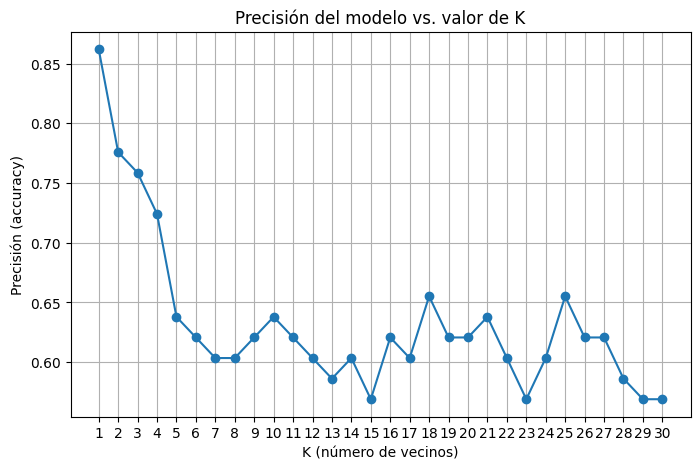

In [41]:
# Se crea una figura para graficar la precisión en función de los valores de k
plt.figure(figsize=(8, 5))
# Se grafica la relación entre los valores de K y la precisión obtenida
# marker="o" agrega puntos circulares en cada valor de K para mejor visualización
plt.plot(list(valores_k), precisiones, marker="o")
# Se define el título de la gráfica
plt.title("Precisión del modelo vs. valor de K")
# Se etiqueta el eje X (valores de K, es decir, número de vecinos)
plt.xlabel("K (número de vecinos)")
# Se etiqueta el eje Y (rendimiento del modelo medido como accuracy)
plt.ylabel("Precisión (accuracy)")
# Se aseguran marcas explícitas en el eje X para cada valor de K evaluado
plt.xticks(list(valores_k))
# Se activa la cuadrícula para facilitar la lectura de la gráfica
plt.grid(True)
# Se muestra la gráfica en pantalla
plt.show()


In [42]:
# Se identifica el índice del valor máximo dentro de la lista de precisiones
# np.argmax devuelve la posición donde la precisión es más alta
indice_mejor = np.argmax(precisiones)
# Se selecciona el valor de K correspondiente a ese índice
# Es decir, el K que obtuvo la mejor precisión en el conjunto de prueba
mejor_k = list(valores_k)[indice_mejor]
print(f"Mejor valor de K encontrado: {mejor_k} (precisión = {max(precisiones):.4f})")

Mejor valor de K encontrado: 1 (precisión = 0.8621)


In [43]:
# Se crea el modelo final de K-Nearest Neighbors utilizando el mejor valor de K encontrado
# n_neighbors=mejor_k asegura que el modelo use la configuración con mejor rendimiento
# metric="euclidean" indica que la distancia entre puntos se calcula con distancia euclidiana
modelo_final = KNeighborsClassifier(n_neighbors=mejor_k, metric="euclidean")
# Se entrena el modelo final con los datos de entrenamiento escalados
# X_train_scaled: variables de entrada normalizadas
# y_train: etiquetas correspondientes a cada observación
modelo_final.fit(X_train_scaled, y_train)
# Se realizan predicciones finales sobre el conjunto de prueba escalado
# Este es el modelo ya optimizado con el mejor valor de K
y_pred_final = modelo_final.predict(X_test_scaled)
print(f"Precisión final del modelo (K={mejor_k}): {accuracy_score(y_test,y_pred_final):.4f}")

Precisión final del modelo (K=1): 0.8621


In [44]:
# Se imprime un reporte completo de evaluación del modelo de clasificación
# classification_report incluye métricas como:
# - precision (exactitud por clase)
# - recall (sensibilidad por clase)
# - f1-score (balance entre precision y recall)
# - support (número de ejemplos reales por clase)
print(classification_report(y_test, y_pred_final))

              precision    recall  f1-score   support

           1       0.67      1.00      0.80         2
           2       0.83      0.83      0.83         6
           3       0.92      0.92      0.92        12
           4       1.00      0.94      0.97        16
           5       0.83      0.77      0.80        13
           6       0.57      0.80      0.67         5
           7       1.00      0.75      0.86         4

    accuracy                           0.86        58
   macro avg       0.83      0.86      0.83        58
weighted avg       0.88      0.86      0.87        58



In [45]:
# Predicción a partir de nuevos datos ['Val MOVS', 'Val MAT', 'Val CRP', 'Val SOL', 'Val M/U']
Colegio_nuevo = pd.DataFrame({
    "Val MOVS": [1],
    "Val MAT": [2],
    "Val CRP": [5],
    "Val SOL": [2],
    "Val M/U": [1]
})
# Se estandarizan los nuevos datos (fruta_nueva) usando el mismo scaler entrenado
# Es importante usar transform (no fit_transform) para mantener la misma escala del entrenamiento
colegio_nuevo_escalado = scaler.transform(Colegio_nuevo)
# Se realiza la predicción de la clase para la nueva observación
# El modelo devuelve la clase más probable según los vecinos cercanos
prediccion = modelo_final.predict(colegio_nuevo_escalado)
# Se obtienen las probabilidades asociadas a cada clase
# predict_proba muestra qué tan probable es que la muestra pertenezca a cada categoría
probabilidades = modelo_final.predict_proba(colegio_nuevo_escalado)
print("Clase predicha:", prediccion[0])
print("Probabilidades por clase:")
for clase, prob in zip(modelo_final.classes_, probabilidades[0]):
    print(f"  {clase}: {prob:.2%}")

Clase predicha: 4
Probabilidades por clase:
  1: 0.00%
  2: 0.00%
  3: 0.00%
  4: 100.00%
  5: 0.00%
  6: 0.00%
  7: 0.00%


In [ ]:
# Comparar precisión en train vs test para descartar overfitting
y_train_pred = modelo_final.predict(X_train_scaled)
precision_train = accuracy_score(y_train, y_train_pred)
precision_test = accuracy_score(y_test, y_pred_final)

print(f"Precisión en entrenamiento: {precision_train:.4f}")
print(f"Precisión en prueba: {precision_test:.4f}")

Precisión en entrenamiento: 1.0000
Precisión en prueba: 0.8621
